# Demo Incremental DBSCAN

---
## PHẦN 1. DỮ LIỆU VÀ GOM CỤM BAN ĐẦU

#### **1.0. CHUẨN BỊ**

In [1]:
## Thư viện và thư mục gốc repo (mở notebook từ gốc repo hay từ notebooks/ đều được; mọi đường dẫn tính từ gốc repo)
import copy
import os
import platform
import sys
import time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display


def repo_root(start=None):
    here = Path(start or Path.cwd()).resolve()
    for d in (here, *here.parents):
        if (d / 'src' / 'clustering').is_dir():
            return d
    raise FileNotFoundError('không thấy src/clustering: hãy mở notebook bên trong repo')


ROOT = repo_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option('display.width', 160)
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__,
      '| matplotlib', matplotlib.__version__, '| scikit-learn', sklearn.__version__)

Python 3.13.2 | numpy 2.5.3 | pandas 2.2.3 | matplotlib 3.10.1 | scikit-learn 1.6.1


In [2]:
## Code của nhóm trong src/; sklearn (DBSCAN qua baseline/, KMeans, StandardScaler, ARI) chỉ dùng để đối chiếu
from src.clustering.dbscan import DBSCAN
from src.experiments.engine import IncrementalEngine
from src.preprocessing.cleaning import clean_card_table, quality_report
from src.preprocessing.scaler import ManualScaler
from src.preprocessing.stream_scaling import stream_coordinates
from src.visualization import ClusterVisualizer, plot_algorithm_contrast, plot_k_distance
from src.visualization.plotter import snapshot_from_model
from baseline.dataset_comparison import DATASETS, load
from baseline.sklearn_dbscan import ambiguous_by_step, compare_partitions, fit_full_dbscan, read_stream
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
print(' -> '.join(c.__name__ for c in IncrementalEngine.__mro__[:-1]))

IncrementalEngine -> IncrementalDBSCAN -> DBSCAN


#### **1.1. DỮ LIỆU**

In [3]:
## Bản đồ ATM: chỉ dùng hai cột tọa độ x_km, y_km; hotspot_id là nhãn thật (6 điểm nóng, -1 là giao dịch lẻ)
atm = pd.read_csv('data/raw/bank_geo/atm_txn_2d.csv', encoding='utf-8')
xy_atm, nhan_that_atm = atm[['x_km', 'y_km']].to_numpy(), atm['hotspot_id'].to_numpy()
print(f'{len(atm)} dòng, {atm.shape[1]} cột | số điểm theo nhãn thật:', dict(sorted(Counter(nhan_that_atm.tolist()).items())))

1200 dòng, 11 cột | số điểm theo nhãn thật: {-1: 138, 0: 204, 1: 150, 2: 222, 3: 90, 4: 228, 5: 168}


In [4]:
## Bảng thẻ thô: 1.500 dòng, 5 đặc trưng số; báo cáo chất lượng trước khi làm sạch
the_tho = pd.read_csv('data/raw/bank_card/card_txn_5d.csv', encoding='utf-8')
khach = pd.read_csv('data/raw/bank_card/customers.csv', encoding='utf-8')
quan = pd.read_csv('data/raw/bank_geo/districts.csv', encoding='utf-8')
DAC_TRUNG = ['amount_vnd', 'hour_of_day', 'distance_from_home_km', 'txns_last_7d', 'merchant_risk_score']
bao_cao = quality_report(the_tho, khach, quan)
bao_cao = bao_cao[bao_cao['n_rows'] > 0].assign(share=lambda d: (100 * d['share']).round(2)).rename(columns={'share': '% dòng'})
bao_cao

,check,column,n_rows,% dòng
0,missing_value,amount_vnd,23,1.53
1,missing_value,hour_of_day,22,1.47
2,missing_value,distance_from_home_km,18,1.20
3,missing_value,txns_last_7d,31,2.07
4,missing_value,merchant_risk_score,18,1.20
5,duplicate_row_exact_copy,(whole row),8,0.53
6,duplicate_txn_id,txn_id,8,0.53
7,inconsistent_spelling_or_case,channel,104,6.93
8,mixed_timestamp_format_dd_mm_yyyy,timestamp,30,2.00
9,impossible_timestamp,timestamp,6,0.40


#### **1.2. TIỀN XỬ LÝ**

In [5]:
## Làm sạch bằng hàm của nhóm: bỏ dòng trùng, chuẩn hóa kênh, sửa giờ, điền thiếu theo nhóm (học trên D0 = 500 giao dịch sớm nhất), gắn cờ lỗi
the_sach, _ = clean_card_table(the_tho, khach, quan)
print('trước:', len(the_tho), 'dòng | sau:', len(the_sach), 'dòng | còn ô thiếu:', int(the_sach[DAC_TRUNG].isna().sum().sum()))
pd.Series({'thời điểm không hợp lệ (gắn cờ)': int((the_sach['ts_status'] == 'impossible').sum()),
           'giờ thiếu, lấy lại từ thời điểm': int(the_tho.drop_duplicates()['hour_of_day'].isna().sum()),
           'ô số điền bằng trung vị nhóm': int(the_sach.filter(like='imp_').sum().sum()),
           'thiếu nhóm hàng (điền UNKNOWN)': int(the_sach['category_missing'].sum()),
           'dòng có mã khách lạ (gắn cờ)': int(the_sach['unknown_customer'].sum()),
           'dòng có mã quận sai (gắn cờ)': int(the_sach['invalid_district'].sum()),
           'số kênh sau chuẩn hóa': the_sach['channel'].nunique()}, name='số lượng').to_frame()

trước: 1500 dòng | sau: 1492 dòng | còn ô thiếu: 0


,số lượng
thời điểm không hợp lệ (gắn cờ),6
"giờ thiếu, lấy lại từ thời điểm",22
ô số điền bằng trung vị nhóm,90
thiếu nhóm hàng (điền UNKNOWN),18
dòng có mã khách lạ (gắn cờ),18
dòng có mã quận sai (gắn cờ),5
số kênh sau chuẩn hóa,4


In [6]:
## Chuẩn hóa z-score bằng ManualScaler tự cài (cột log10 số tiền tạo ở bước làm sạch), chỉ fit trên 500 dòng D0; đối chiếu StandardScaler
COT_Z = ['log10_amount_vnd'] + DAC_TRUNG[1:]
la_d0 = the_sach['is_d0'].to_numpy()
bo_chuan_hoa = ManualScaler('standard').fit(the_sach.loc[la_d0, COT_Z])
Z_the = bo_chuan_hoa.transform(the_sach[COT_Z])
lech = np.abs(StandardScaler().fit(the_sach.loc[la_d0, COT_Z]).transform(the_sach[COT_Z]) - Z_the).max()
print('sai khác lớn nhất so với sklearn:', lech)
pd.DataFrame({'trung bình D0': bo_chuan_hoa.center_, 'độ lệch chuẩn D0': bo_chuan_hoa.scale_,
              'độ lệch chuẩn sau chuẩn hóa (D0)': Z_the[la_d0].std(axis=0)}, index=COT_Z).round(3)

sai khác lớn nhất so với sklearn: 0.0


,trung bình D0,độ lệch chuẩn D0,độ lệch chuẩn sau chuẩn hóa (D0)
log10_amount_vnd,5.588,0.789,1.0
hour_of_day,12.913,6.749,1.0
distance_from_home_km,17.720,56.553,1.0
txns_last_7d,7.772,5.580,1.0
merchant_risk_score,0.341,0.212,1.0


#### **1.3. CHỌN EPS VÀ MINPTS**

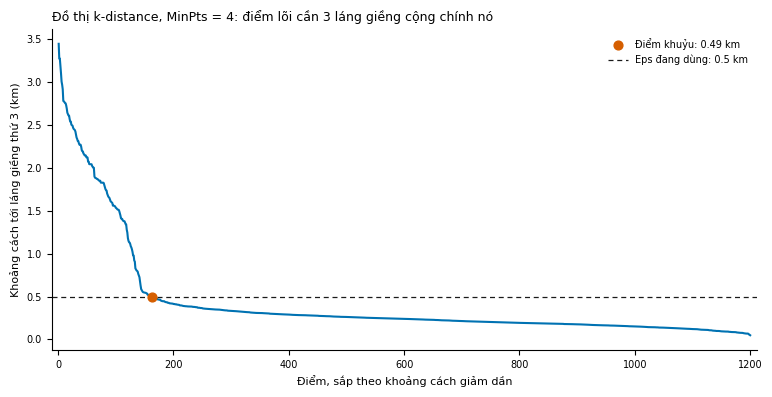

In [7]:
## Đồ thị k-distance của bản đồ ATM với MinPts = 4 (láng giềng thứ 3, không tính chính nó): khuỷu ở khoảng 0,49 km
hinh = plot_k_distance(xy_atm, min_pts=4, eps=0.5)
hinh.set_size_inches(8, 4.2)

In [8]:
## Thử Eps quanh khuỷu bằng DBSCAN của nhóm: 0,4 km cụm còn vỡ vụn, từ 0,5 km số cụm giữ ở 6 nên lấy 0,5; ARI chỉ để kiểm tra, không dùng để chọn
cac_mo_hinh, dong = {}, []
for eps in (0.4, 0.5, 0.6, 0.7):
    t0 = time.perf_counter()
    cac_mo_hinh[eps] = DBSCAN(eps, 4).fit(xy_atm)
    giay = time.perf_counter() - t0
    nhan = np.array(cac_mo_hinh[eps].get_labels())
    dong.append({'Eps (km)': eps, 'số cụm': len(set(nhan.tolist()) - {-1}), 'số nhiễu': int((nhan == -1).sum()),
                 'ARI (chỉ kiểm tra)': round(adjusted_rand_score(nhan_that_atm, nhan), 3), 'giây': round(giay, 2)})
pd.DataFrame(dong)

,Eps (km),số cụm,số nhiễu,ARI (chỉ kiểm tra),giây
0,0.4,13,162,0.810,1.82
1,0.5,6,142,0.993,1.83
2,0.6,6,141,0.995,1.83
3,0.7,6,137,0.988,1.96


#### **1.4. GOM CỤM BAN ĐẦU BẰNG DBSCAN TỰ CÀI**

In [9]:
## DBSCAN của nhóm ở Eps = 0,5 km (mô hình vừa fit ở ô trên) so với DBSCAN của sklearn: cùng cách chia cụm, cùng tập nhiễu, cùng tập lõi
mo_hinh_atm = cac_mo_hinh[0.5]
anh_atm = snapshot_from_model(mo_hinh_atm)
t0 = time.perf_counter()
nhan_sk, loai_sk = fit_full_dbscan(xy_atm, 0.5, 4)
giay_sk = time.perf_counter() - t0
ss = compare_partitions(anh_atm['labels'], nhan_sk, types_a=anh_atm['point_types'], types_b=loai_sk)
print(f"ARI giữa hai bản: {ss['ari']} | cùng tập nhiễu: {ss['noise_equal']} | cùng tập lõi: {ss['core_equal']}")
print(f"thời gian fit: nhóm {dong[1]['giây']} giây (Python thuần, khoảng n² phép tính khoảng cách) | sklearn {giay_sk:.3f} giây (mã biên dịch)")
print('một điểm là một đối tượng DataPoint:', mo_hinh_atm.points[0])

ARI giữa hai bản: 1.0 | cùng tập nhiễu: True | cùng tập lõi: True
thời gian fit: nhóm 1.83 giây (Python thuần, khoảng n² phép tính khoảng cách) | sklearn 0.006 giây (mã biên dịch)
một điểm là một đối tượng DataPoint: DataPoint(id=0, coords=[16.031, 6.19], cluster=0, type=CORE, neighbor_ids=[0, 193, 221, 568, 620, 828, 853, 958, 1196])


,thuật toán,ARI (nhiễu là một lớp),ARI trên 1062 điểm thuộc điểm nóng,số cụm,số nhiễu
0,DBSCAN của nhóm,0.993,0.995,6,142
1,KMeans (k = 6),0.583,0.692,6,0


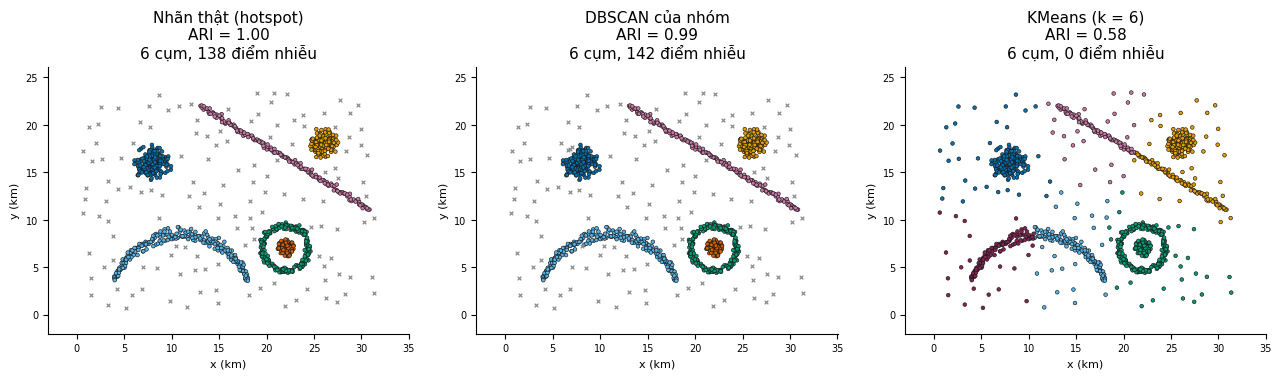

In [10]:
## Cùng bản đồ: nhãn thật, DBSCAN của nhóm và KMeans k = 6 (k lấy từ nhãn thật); KMeans chia theo tâm gần nhất nên gộp vòng chợ với cụm bên trong, cắt đôi lưỡi liềm và dải quốc lộ
nhan_atm = np.array(mo_hinh_atm.get_labels())
nhan_kmeans = KMeans(6, n_init=10, random_state=0).fit_predict(xy_atm)
co_cum = nhan_that_atm != -1
cac_ket_qua = {'DBSCAN của nhóm': nhan_atm, 'KMeans (k = 6)': nhan_kmeans}
display(pd.DataFrame([{'thuật toán': ten, 'ARI (nhiễu là một lớp)': round(adjusted_rand_score(nhan_that_atm, nhan), 3),
                       f'ARI trên {int(co_cum.sum())} điểm thuộc điểm nóng': round(adjusted_rand_score(nhan_that_atm[co_cum], nhan[co_cum]), 3),
                       'số cụm': len(set(nhan.tolist()) - {-1}), 'số nhiễu': int((nhan == -1).sum())} for ten, nhan in cac_ket_qua.items()]))
diem = {ten: adjusted_rand_score(nhan_that_atm, nhan) for ten, nhan in cac_ket_qua.items()}
hinh = plot_algorithm_contrast(xy_atm, nhan_that_atm, cac_ket_qua, scores={'Nhãn thật (hotspot)': 1.0, **diem}, ncols=3)
hinh.set_size_inches(13, 4.8)
for truc in hinh.axes:
    truc.title.set_fontsize(11)

In [11]:
## DBSCAN của nhóm trên bảng thẻ 5 chiều (Eps 0,65, MinPts 10 đặt khi sinh dữ liệu, có dùng nhãn nên ARI là cận trên); so với sklearn
mo_hinh_the = DBSCAN(0.65, 10).fit(Z_the)
anh_the = snapshot_from_model(mo_hinh_the)
nhan_the = np.asarray(anh_the['labels'])
bat_thuong = the_sach['segment_id'].to_numpy() == -1
so_nhieu, nhieu_bt = int((nhan_the == -1).sum()), int((nhan_the[bat_thuong] == -1).sum())
nhan_sk_the, loai_sk_the = fit_full_dbscan(Z_the, 0.65, 10)
ss_the = compare_partitions(nhan_the, nhan_sk_the, types_a=anh_the['point_types'], types_b=loai_sk_the)
print(f"{Z_the.shape[1]} chiều, {len(nhan_the)} giao dịch | {len(set(nhan_the.tolist()) - {-1})} cụm | ARI so với phân khúc thật "
      f"{adjusted_rand_score(the_sach['segment_id'], nhan_the):.3f}")
print(f"{so_nhieu} nhiễu = {nhieu_bt}/{int(bat_thuong.sum())} giao dịch bất thường + {so_nhieu - nhieu_bt} giao dịch thường")
print(f"khớp sklearn: ARI {ss_the['ari']} | cùng tập nhiễu: {ss_the['noise_equal']} | cùng tập lõi: {ss_the['core_equal']}")

5 chiều, 1492 giao dịch | 4 cụm | ARI so với phân khúc thật 0.997
19 nhiễu = 15/15 giao dịch bất thường + 4 giao dịch thường
khớp sklearn: ARI 1.0 | cùng tập nhiễu: True | cùng tập lõi: True


#### **1.5. SO SÁNH VỚI SKLEARN TRÊN NHIỀU BỘ DỮ LIỆU**

In [12]:
## DBSCAN của nhóm so với sklearn trên thêm bốn bộ dữ liệu đã chuẩn hóa (cùng Eps, MinPts với thí nghiệm so sánh tám bộ)
dong = []
for ten, duong_dan, cot_nhan, eps, minpts in DATASETS:
    if ten not in ('moons', 'rings', 'blobs có nhiễu', 'blobs 5D'):
        continue
    X, y = load(duong_dan, cot_nhan)
    t0 = time.perf_counter()
    anh = snapshot_from_model(DBSCAN(eps, minpts).fit(X))
    giay = time.perf_counter() - t0
    nhan_sk, loai_sk = fit_full_dbscan(X, eps, minpts)
    ss = compare_partitions(anh['labels'], nhan_sk, types_a=anh['point_types'], types_b=loai_sk)
    dong.append({'bộ dữ liệu': ten, 'số chiều': X.shape[1], 'số điểm': len(X), 'Eps': eps, 'MinPts': minpts,
                 'khớp sklearn (chia cụm, nhiễu, lõi)': bool(ss['partition_equal'] and ss['core_equal']),
                 'ARI so với nhãn thật': round(adjusted_rand_score(y, anh['labels']), 3), 'giây': round(giay, 2)})
pd.DataFrame(dong)

,bộ dữ liệu,số chiều,số điểm,Eps,MinPts,"khớp sklearn (chia cụm, nhiễu, lõi)",ARI so với nhãn thật,giây
0,moons,2,500,0.21,8,True,0.972,0.32
1,rings,2,500,0.30,8,True,1.000,0.32
2,blobs có nhiễu,2,500,0.24,8,True,0.930,0.32
3,blobs 5D,5,860,0.80,10,True,0.994,1.25


#### **1.6. TẬP BAN ĐẦU CỦA LUỒNG CẬP NHẬT**

In [13]:
## Luồng ATM dựng sẵn (khác bản đồ 1.200 điểm): 529 điểm ban đầu gồm 2 điểm nóng nền và 43 mảnh ghép từ 8 ví dụ lý thuyết, sau đó 119 bước chèn hoặc xóa
tap_dau_atm, cap_nhat_atm, tham_so_atm, cot_atm = read_stream('data/raw/bank_geo/atm_stream')
mo_hinh = IncrementalEngine(tham_so_atm['eps_km'], tham_so_atm['minpts']).fit(stream_coordinates(tham_so_atm, tap_dau_atm, cot_atm))
mo_hinh_ban_dau = copy.deepcopy(mo_hinh)
anh_dau = mo_hinh.snapshot()
nhan_sk, loai_sk = fit_full_dbscan(stream_coordinates(tham_so_atm, tap_dau_atm, cot_atm), tham_so_atm['eps_km'], tham_so_atm['minpts'])
ss = compare_partitions(anh_dau['labels'], nhan_sk, ignore_ids=ambiguous_by_step(tham_so_atm, cap_nhat_atm)[0],
                        types_a=anh_dau['point_types'], types_b=loai_sk)
print(f"mo_hinh: {mo_hinh.n_points} điểm, {mo_hinh.n_clusters} cụm, {mo_hinh.n_noise} nhiễu | luồng có {len(cap_nhat_atm)} bước "
      f"({int((cap_nhat_atm['op'] == 'insert').sum())} chèn, {int((cap_nhat_atm['op'] == 'delete').sum())} xóa)")
print(f"khớp sklearn ở bước 0: ARI {ss['ari']} | cùng tập nhiễu: {ss['noise_equal']} | cùng tập lõi: {ss['core_equal']}")

mo_hinh: 529 điểm, 44 cụm, 24 nhiễu | luồng có 119 bước (69 chèn, 50 xóa)
khớp sklearn ở bước 0: ARI 1.0 | cùng tập nhiễu: True | cùng tập lõi: True


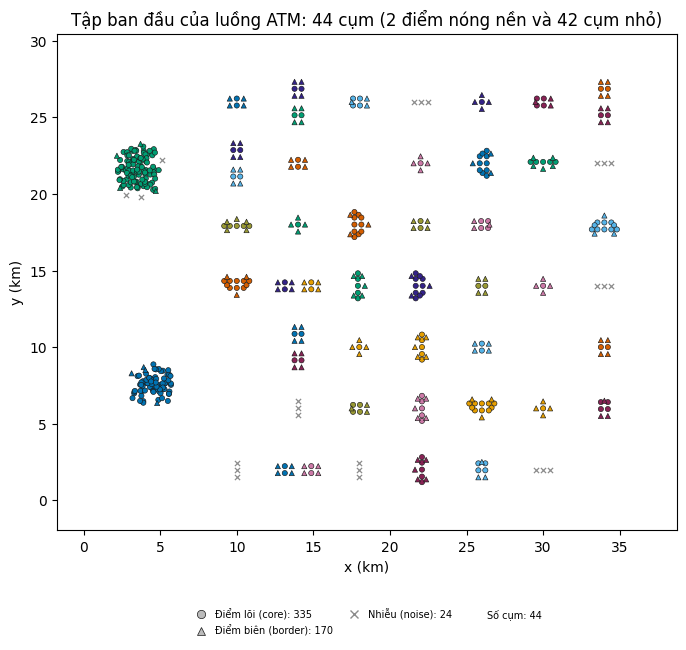

In [14]:
## Trạng thái ban đầu trên bản đồ: hình tròn là lõi, tam giác là biên, dấu x là nhiễu
hinh, truc = plt.subplots(figsize=(8, 7))
truc = ClusterVisualizer(point_size=14).plot_2d(mo_hinh, ax=truc, fill=None, axis_labels=('x (km)', 'y (km)'),
                                                title=f'Tập ban đầu của luồng ATM: {mo_hinh.n_clusters} cụm (2 điểm nóng nền và {mo_hinh.n_clusters - 2} cụm nhỏ)')
truc.title.set_fontsize(12)

---
## PHẦN 2. CẬP NHẬT TĂNG DẦN